In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.svm import SVC
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

nyc = pd.read_csv("C:\\Users\\user\\Desktop\\uni\\4sem\\gpvy\\data.csv")
nyc.columns = ['Date', 'Temperature', 'Anomaly']
nyc.Date =nyc.Date.floordiv(100)
nyc.head()


,Date,Temperature,Anomaly
0,1895,29.7,-4.3
1,1896,28.5,-5.5
2,1897,29.3,-4.7
3,1898,33.9,-0.1
4,1899,29.8,-4.2


In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(nyc.Date.values.reshape(-1, 1), nyc.Temperature.values, random_state = 11)

In [4]:
X_train.shape

(93, 1)

In [5]:
X_test.shape

(31, 1)

In [6]:
from sklearn.linear_model import LinearRegression

linear_regression = LinearRegression()
linear_regression.fit(X=X_train, y=y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
linear_regression.coef_

array([0.0264037])

In [8]:
predict = (lambda x: linear_regression.coef_*x + linear_regression.intercept_)

In [9]:
predicted = linear_regression.predict(X_test)
expected = y_test
for p, e in zip(predicted[::5], expected[::5]):
    print(f"predicted: {p:.2f}, expected: {e:.2f}")

predicted: 32.03, expected: 26.00
predicted: 33.17, expected: 30.00
predicted: 30.87, expected: 31.80
predicted: 31.22, expected: 39.60
predicted: 32.30, expected: 28.10
predicted: 31.74, expected: 28.10
predicted: 30.79, expected: 33.10


In [10]:
predict(2019)

array([33.38089994])

In [11]:
predict(1890)

array([29.97482255])

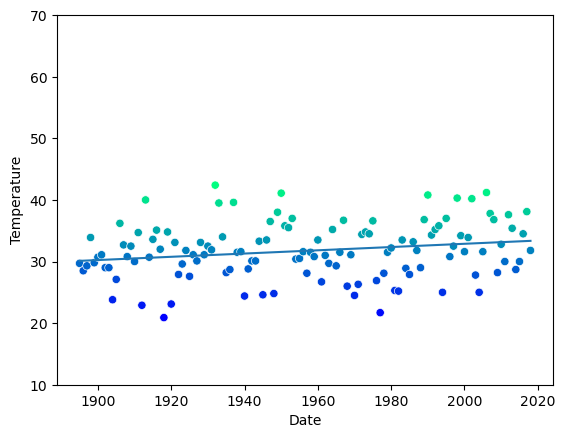

In [12]:
axes = sns.scatterplot(data=nyc, x = 'Date', y = 'Temperature', hue = 'Temperature', palette = 'winter', legend = False)
axes.set_ylim(10,70)
x = np.array([min(nyc.Date.values), max(nyc.Date.values)])
y = predict(x)
line = plt.plot(x,y)

In [13]:
def plot_decision_regions(X, y, classifier, test_idx=None, resolution=0.02):
    markers = ('s', 'x', 'o', '^', 'v')
    colors  = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap    = ListedColormap(colors[:len(np.unique(y))])
 
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
 
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
 
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8, 
                    c=colors[idx],
                    marker=markers[idx], 
                    label=cl, 
                    )
 
    if test_idx:
        X_test, y_test = X[test_idx, :], y[test_idx]
        plt.scatter(X_test[:, 0],
                    X_test[:, 1],
                    c='', 
                    alpha=1.0,
                    linewidth=1, 
                    marker='o', 
                    s=100, 
                    label='test set')

Text(0.5, 1.0, 'SVC (RBF kernel) on XOR  data')

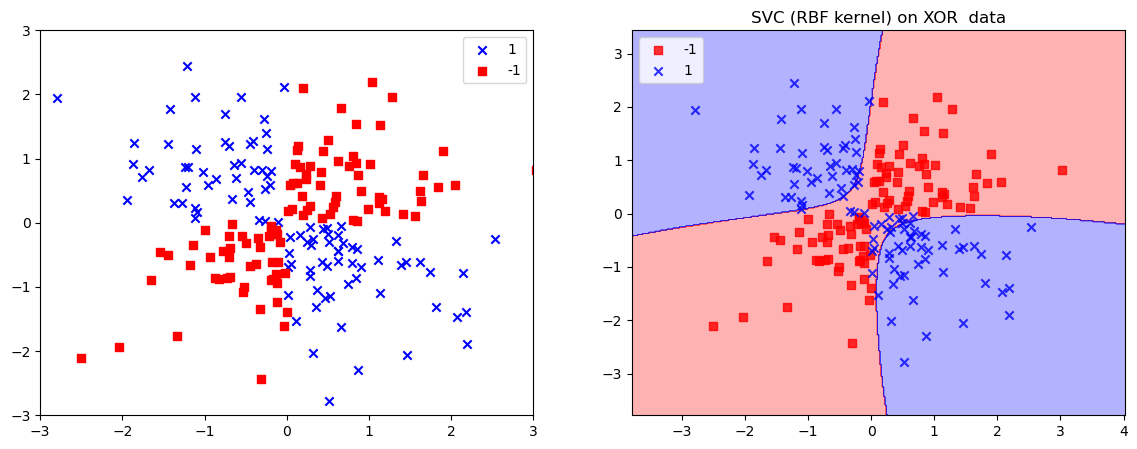

In [14]:
np.random.seed(1)
X_xor = np.random.randn(200, 2)
y_xor = np.logical_xor(X_xor[:, 0] > 0, X_xor[:, 1] > 0)
y_xor = np.where(y_xor, 1, -1)
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
plt.sca(axes[0])
plt.scatter(X_xor[y_xor == 1,  0], X_xor[y_xor == 1,  1],
            c='b', marker='x', label='1')
plt.scatter(X_xor[y_xor == -1, 0], X_xor[y_xor == -1, 1],
            c='r', marker='s', label='-1')
plt.xlim([-3, 3]); plt.ylim([-3, 3])
plt.legend(loc='best')

 
svm = SVC(kernel='rbf', random_state=1, gamma=0.10, C=10.0)
svm.fit(X_xor, y_xor)
 
plt.sca(axes[1])
plot_decision_regions(X_xor, y_xor, classifier=svm)
plt.legend(loc='upper left')
plt.title('SVC (RBF kernel) on XOR  data')



In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.inspection import DecisionBoundaryDisplay

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)



              precision    recall  f1-score   support

           0       1.00      0.86      0.93        43
           1       0.92      1.00      0.96        71

    accuracy                           0.95       114
   macro avg       0.96      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114

Confusion Matrix:
[[37  6]
 [ 0 71]]


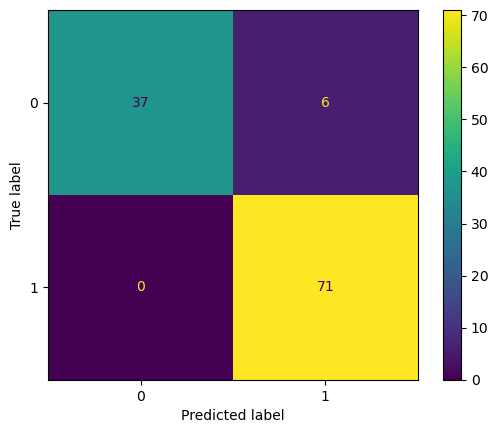

In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
svm = SVC(kernel="rbf", C=10)
svm.fit(X_train, y_train)
y_pred_test_svc = svm.predict(X_test)
svm_test_accuracy  = accuracy_score(y_test, y_pred_test_svc)
print(classification_report(y_test, y_pred_test_svc))

cm = confusion_matrix(y_test, y_pred_test_svc)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



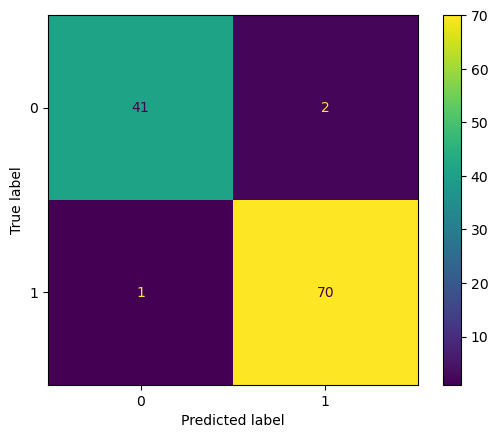

In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)

y_pred_test_knn = knn.predict(X_test)
knn_test_accuracy  = accuracy_score(y_test, y_pred_test_knn)

print(classification_report(y_test, y_pred_test_knn))

cm = confusion_matrix(y_test, y_pred_test_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()


              precision    recall  f1-score   support

           0       1.00      0.93      0.96        43
           1       0.96      1.00      0.98        71

    accuracy                           0.97       114
   macro avg       0.98      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



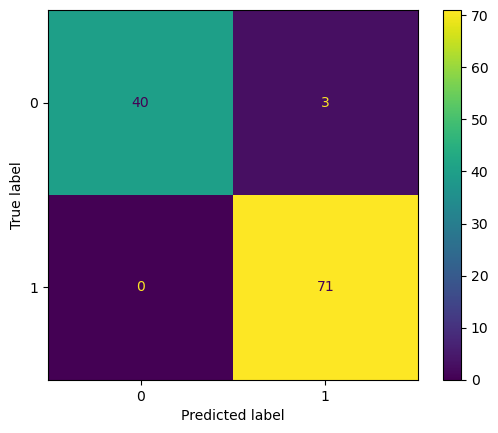

In [21]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

y_pred_test_gnb = gnb.predict(X_test)
gnb_test_accuracy  = accuracy_score(y_test, y_pred_test_gnb)

print(classification_report(y_test, y_pred_test_gnb))

cm = confusion_matrix(y_test, y_pred_test_gnb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

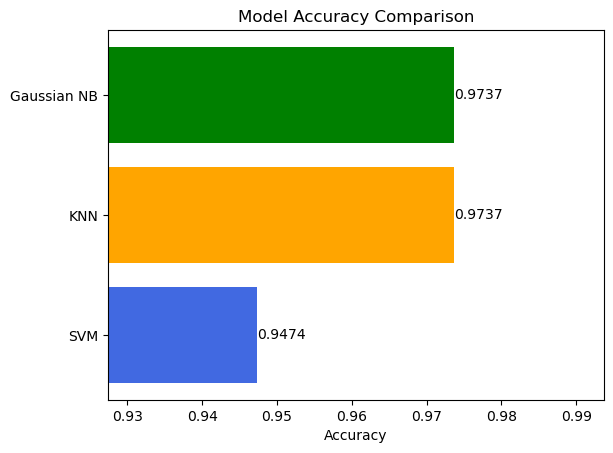

In [22]:

models = ['SVM', 'KNN', 'Gaussian NB']
accuracies = [svm_test_accuracy, knn_test_accuracy, gnb_test_accuracy]

plt.figure()
colors = ['royalblue', 'orange', 'green']
plt.barh(models, accuracies, color=colors)
plt.xlim(min(accuracies) - 0.02, max(accuracies) + 0.02)

plt.xlabel("Accuracy")
plt.title("Model Accuracy Comparison")

for i, v in enumerate(accuracies):
    plt.text(v, i, f"{v:.4f}", va='center')

plt.show()